In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from hidro_tools import modelo_tanques
from pysheds.grid import Grid
from pysheds.view import Raster, ViewFinder
from pathlib import Path
import xarray as xr
import matplotlib.colors as colors
import rioxarray 
import glob
import re

In [9]:
# Lectura de datos
df = pd.read_csv(
    '0022057010-Q_MEDIA_D.csv',
    index_col=0,
    parse_dates=True,
    usecols=[0,1]
)
df = df.resample('D').mean()

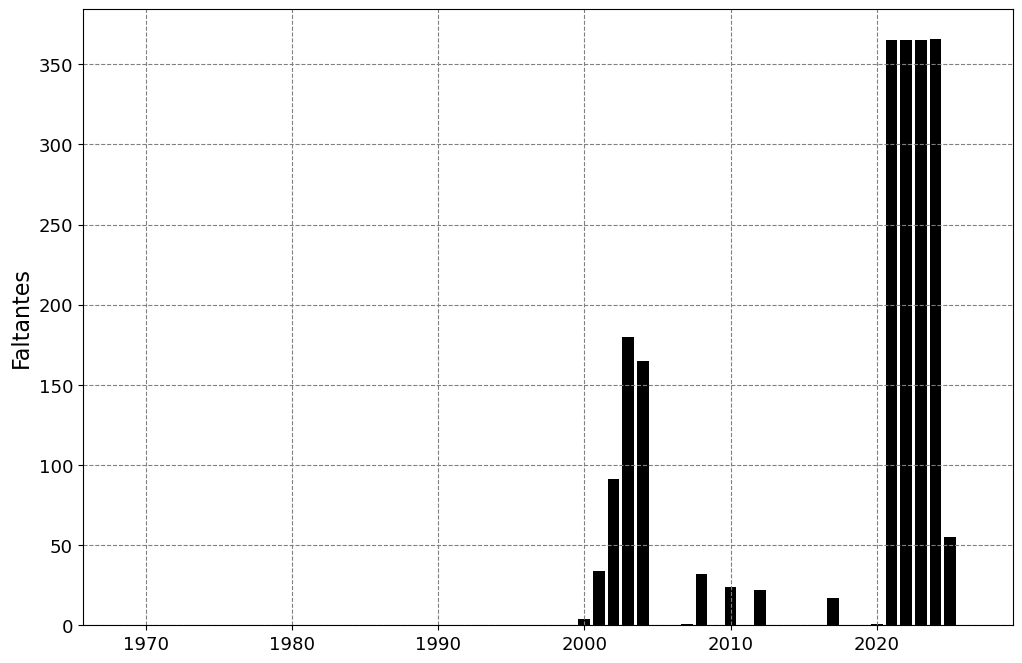

In [15]:
faltantes = df.isna().groupby(df.index.year).sum()
# ploteo de los faltantes
x = faltantes.index
y = faltantes.iloc[:,0]
plt.figure(figsize=(12,8))
plt.bar(x=x,height=y,color='black')
plt.ylabel('Faltantes',fontsize=16)
plt.yticks(size=13)
plt.xticks(size=13)
plt.grid(linestyle='--',color='grey')

## Delimitacion cuenca Piedra de Cobre

In [29]:
crs = 9377
gdf = gpd.read_file('CNE_actualizado')
gdf = gdf.to_crs(crs)
mask = gdf['Codigo'] == '22057010'
est_piedra_cobre = gdf[mask].copy()
lon = est_piedra_cobre.get_coordinates().iloc[0,0]
lat = est_piedra_cobre.get_coordinates().iloc[0,1]

In [53]:
est_piedra_cobre.to_file('estacion_punta_cobre')

In [30]:
# Set plotting style
plt.style.use("bmh")

In [68]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)

dem_9377 = dem.rio.reproject(
    'EPSG:9377',
    resolution=30,   # ajusta a tu resolución original (m); evita celdas no cuadradas o remuestreo no deseado
)

In [136]:
data = dem_9377.data
affine = dem_9377.rio.transform()
crs = dem_9377.rio.crs
# Keep same data type as DEM values for nodata
nodata = data.dtype.type(np.nan)

In [137]:
viewfinder = ViewFinder(affine=affine, shape=data.shape, crs=crs, nodata=nodata)
dem = Raster(data, viewfinder=viewfinder)

In [138]:
# Create grid
grid = Grid.from_raster(dem)

In [139]:
# Detect number of pits in DEM
pits = grid.detect_pits(dem)
npits = np.count_nonzero(pits)

# Check number of pits
print(f"Number of pits found: {npits}")

Number of pits found: 71250


In [140]:
# Fill pits and check they have been filled
pit_filled_dem = grid.fill_pits(dem)
pits = grid.detect_pits(pit_filled_dem)
assert not pits.any()

In [141]:
depressions = grid.detect_depressions(pit_filled_dem)

In [142]:
# Fill depressions - Slow, takes 5-10 minutes...
flooded_dem = grid.fill_depressions(pit_filled_dem)
depressions = grid.detect_depressions(flooded_dem)
assert not depressions.any()

In [143]:
inflated_dem = grid.resolve_flats(flooded_dem, max_iter=1e9, eps=1e-12)

In [144]:
# Compute flow direction based on corrected DEM (D8)
fdir = grid.flowdir(inflated_dem)

# Compute flow accumulation based on computed flow direction
acc = grid.accumulation(fdir)

In [145]:
outlet = (float(lon), float(lat))
# Snap outlet point to nearby cell with high flow accumulation
x_snap, y_snap = grid.snap_to_mask(acc > 1000, outlet)

# Delineate the watershed
catch = grid.catchment(x=x_snap, y=y_snap, fdir=fdir,xytype="coordinate")

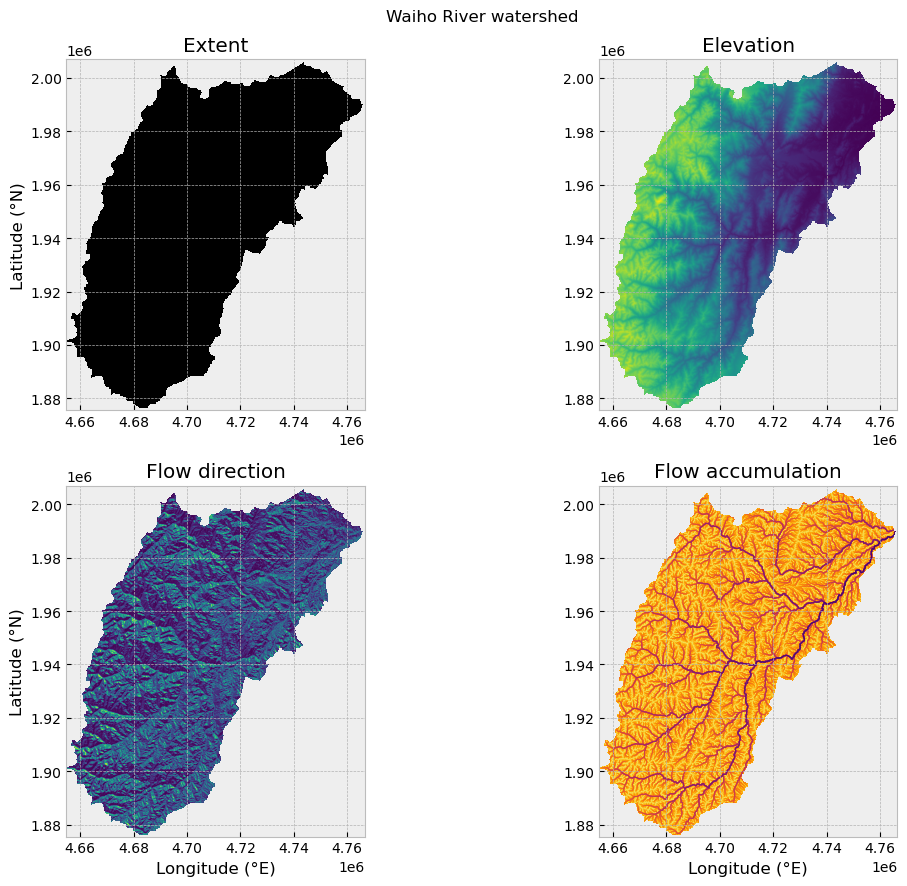

In [146]:
# Clip and set view extents
grid.clip_to(catch)
catch_view = grid.view(catch, nodata=np.nan)
dem_view = grid.view(dem, nodata=np.nan)
fdir_view = grid.view(fdir, nodata=np.nan)
acc_view = grid.view(acc, nodata=np.nan)

# Create figure and plot axes
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.patch.set_alpha(0)

# Plot watershed extent
im = axes[0, 0].imshow(catch_view, extent=grid.extent, zorder=1, cmap="Greys_r")
axes[0, 0].set_title("Extent")
axes[0, 0].set_ylabel("Latitude (°N)")

# Plot watershed elevations
im = axes[0, 1].imshow(dem_view, extent=grid.extent, zorder=1, cmap="viridis")
axes[0, 1].set_title("Elevation")

# Plot watershed flow directions
im = axes[1, 0].imshow(fdir_view, extent=grid.extent, zorder=1, cmap="viridis")
axes[1, 0].set_title("Flow direction")
axes[1, 0].set_xlabel("Longitude (°E)")
axes[1, 0].set_ylabel("Latitude (°N)")

# Plot watershed flow accumulation
im = axes[1, 1].imshow(
    acc_view,
    extent=grid.extent,
    zorder=1,
    cmap="inferno_r",
    norm=colors.LogNorm(1, acc.max()),
)
axes[1, 1].set_title("Flow accumulation")
axes[1, 1].set_xlabel("Longitude (°E)")

# Add a figure title
plt.suptitle("Waiho River watershed")
plt.tight_layout()

In [147]:
# catch = grid.catchment(x=x_out, y=y_out, fdir=fdir, xytype='coordinate')

# 1. Recortar el grid a la extensión de la cuenca
grid.clip_to(catch)

# 2. Vista de la máscara de la cuenca (ya recortada)
catch_view = grid.view(catch, nodata=0)

# 3. Guardar como GeoTIFF (la máscara es booleana, conviene pasarla a uint8)
grid.to_raster(
    catch_view.astype('uint8'),
    'cuenca_saldana_mask.tif',
    target_view=grid.viewfinder,
    blockxsize=256,
    blockysize=256,
    nodata=0,
)

## Modelo Hidrológico 
Se ajustan modelos de lluvia escorrentía Velez et al (2000) y GR4J.
Insumos:
- Precipitación CHIRPS 1981 - 2026 promediada zonalmente a nivel de cuenca
- ETP: Inicialmente Cenicafé, para ajuste inicial, luego se pueden utilizar otras entradas como Turc, Hargreaves o Thornwaite

### Precipitación

In [22]:
das = []
for f in sorted(glob.glob('chirps_tifs/chirps_*.tif')):
    da = rioxarray.open_rasterio(f)
    year = int(re.search(r'chirps_(\d{4})\.tif', f).group(1))
    fechas = pd.date_range(f'{year}-01-01', periods=da.sizes['band'], freq='D')
    das.append(da.assign_coords(band=fechas).rename(band='time'))

pptn = xr.concat(das, dim='time')

In [81]:
# Cargar cuenca
path = 'cuenca_saldana'
cuenca_saldana = gpd.read_file(path)
# Cambiar crs
crs = pptn.rio.crs
cuenca_saldana = cuenca_saldana.to_crs(crs)

In [85]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)
dem = dem.rio.reproject('EPSG:9377', resolution=30)

In [86]:
def clip_a_cuenca(da, gdf):
    g = gdf.to_crs(da.rio.crs)
    return da.rio.clip(g.geometry.values, crs=da.rio.crs, drop=True)

In [88]:
clip_pptn = clip_a_cuenca(pptn, cuenca_saldana)
clip_dem  = clip_a_cuenca(dem, cuenca_saldana)

## Modelo de Tanques

<module 'hidro_tools.modelo_tanques' from 'C:\\Users\\USUARIO\\Desktop\\libreria_hidrologia_v2\\hidro_tools\\modelo_tanques.py'>